In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import io
from google.colab import files
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode, b64encode
from PIL import Image

In [ ]:
os.makedirs('images', exist_ok=True)

print("Please Upload The Required Images:")
print("- little_girl.jpg")
print("- plate2.jpg")

uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('images', filename)
  os.rename(filename, dest)
  print(f"{filename} Uploaded Successfully")

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Please Upload The Required Images:
- little_girl.jpg
- plate2.jpg


Saving little_girl.jpg to little_girl.jpg
Saving plate2.jpg to plate2.jpg
little_girl.jpg Uploaded Successfully
plate2.jpg Uploaded Successfully

Contents Of Images Folder:
['little_girl.jpg', 'plate2.jpg']


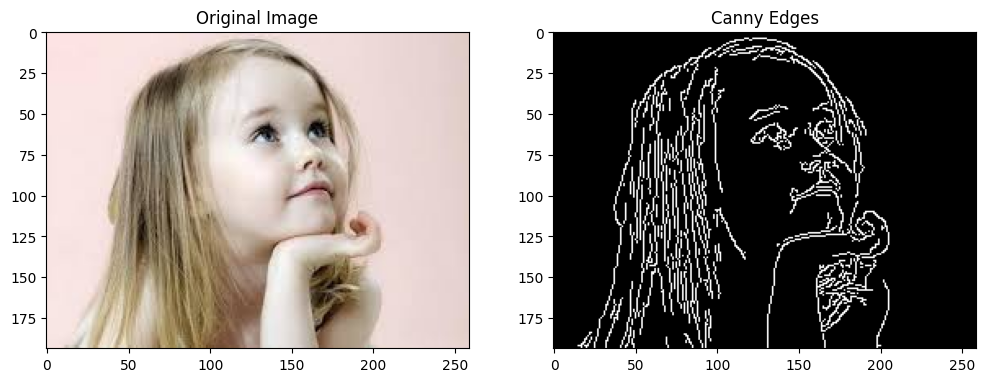

In [ ]:
plt.figure(figsize=(12, 7))

scr = cv2.imread('images/little_girl.jpg')

edges = cv2.Canny(scr, 100, 200)

plt.subplot(1, 2, 1)
plt.imshow(scr[..., ::-1])
plt.title('Original Image')

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap='gray')
plt.title('Canny Edges')

plt.show()

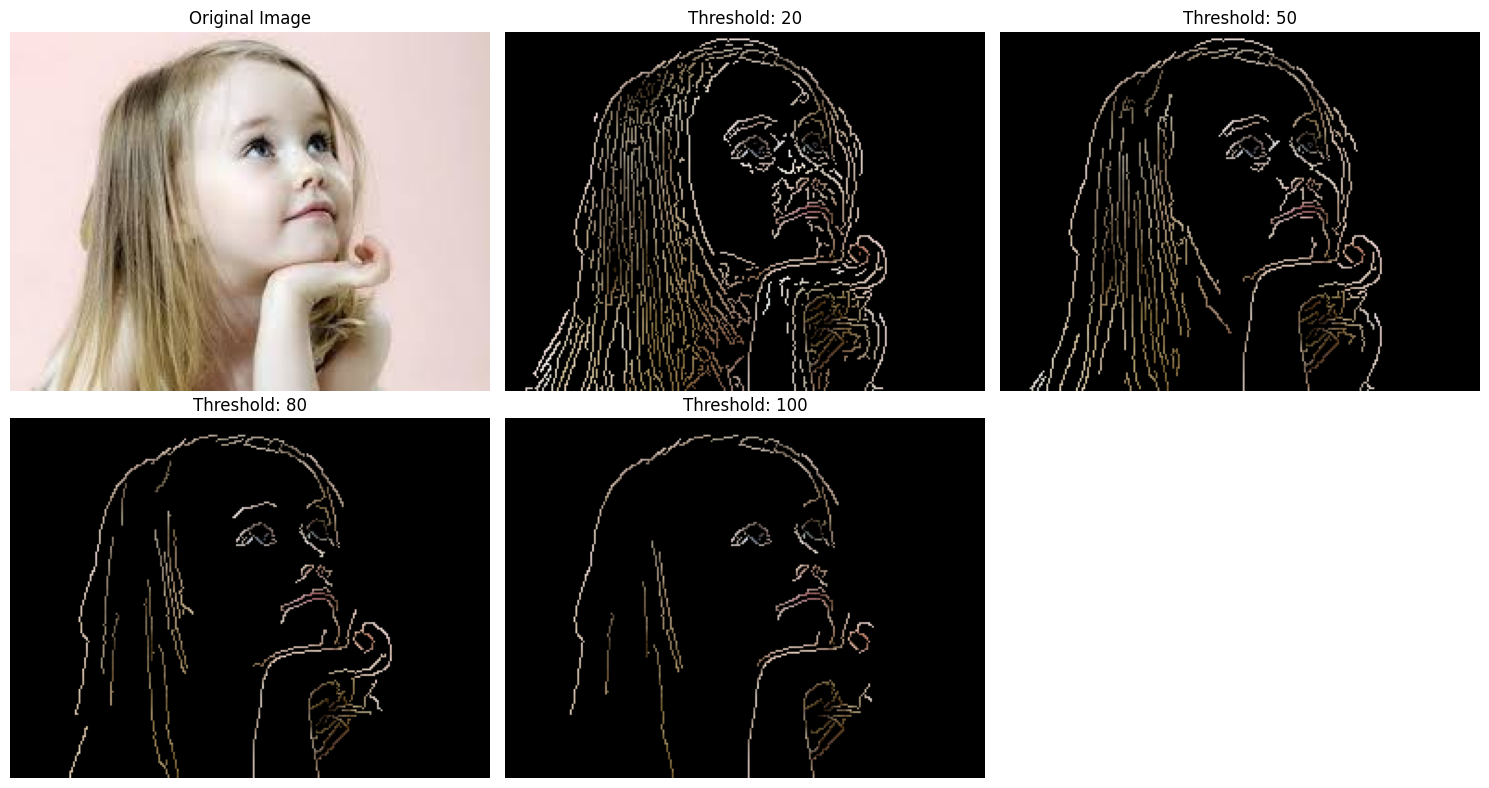

In [ ]:
scr = cv2.imread('images/little_girl.jpg')
gray = cv2.cvtColor(scr, cv2.COLOR_BGR2GRAY)
img_blur = cv2.GaussianBlur(gray, (3, 3), 0)

thresholds = [20, 50, 80, 100]
ratio = 3
kernel_size = 3

plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(scr[..., ::-1])
plt.title('Original Image')
plt.axis('off')

for i, low in enumerate(thresholds):
    edges = cv2.Canny(img_blur, low, low * ratio, kernel_size)
    mask = edges != 0
    dst = scr * (mask[:, :, None].astype(scr.dtype))

    plt.subplot(2, 3, i + 2)
    plt.imshow(dst[..., ::-1])
    plt.title(f'Threshold: {low}')
    plt.axis('off')

plt.tight_layout()
plt.show()

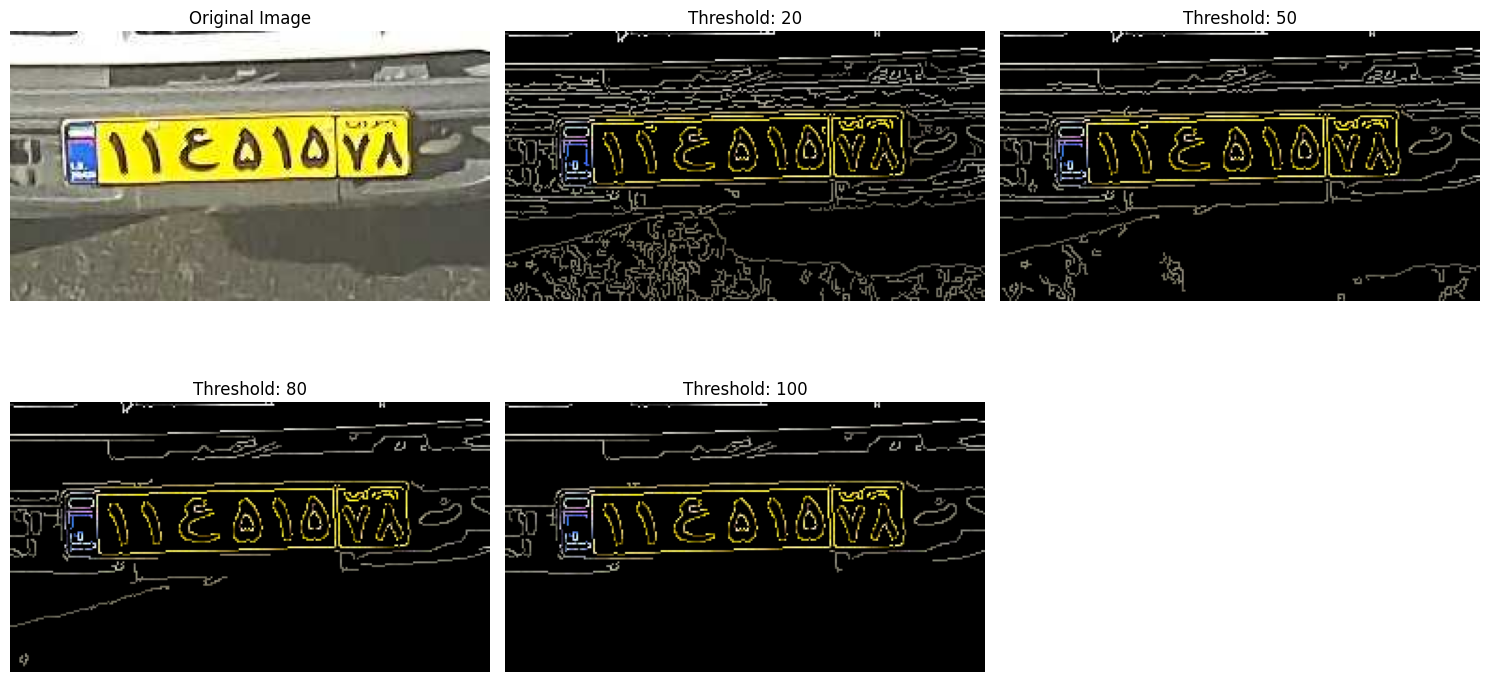

In [ ]:
scr = cv2.imread('images/plate2.jpg')
gray = cv2.cvtColor(scr, cv2.COLOR_BGR2GRAY)
img_blur = cv2.GaussianBlur(gray, (3, 3), 0)

thresholds = [20, 50, 80, 100]
ratio = 3
kernel_size = 3

plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(scr[..., ::-1])
plt.title('Original Image')
plt.axis('off')

for i, low in enumerate(thresholds):
    edges = cv2.Canny(img_blur, low, low * ratio, kernel_size)
    mask = edges != 0
    dst = scr * (mask[:, :, None].astype(scr.dtype))

    plt.subplot(2, 3, i + 2)
    plt.imshow(dst[..., ::-1])
    plt.title(f'Threshold: {low}')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
def js_to_image(js_reply):
  image_bytes = b64decode(js_reply.split(',')[1])
  jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
  img = cv2.imdecode(jpg_as_np, flags=1)
  return img

def bbox_to_bytes(bbox_array):
  bbox_PIL = Image.fromarray(bbox_array)
  io_buf = io.BytesIO()
  bbox_PIL.save(io_buf, format='jpeg')
  bbox_bytes = 'data:image/jpeg;base64,{}'.format((b64encode(io_buf.getvalue()).decode('utf-8')))
  return bbox_bytes

def video_stream():
  js = Javascript('''
    var video;
    var div = null;
    var stream;
    var captureCanvas;
    var imgElement;
    var labelVal = "";

    function removeDom() {
       if (stream) {
         stream.getVideoTracks()[0].stop();
       }
       if (video) video.remove();
       if (div) div.remove();
       video = null;
       div = null;
    }

    function createDom() {
       div = document.createElement('div');
       div.style.border = '2px solid black';
       div.style.padding = '10px';
       div.style.width = '640px';

       const stopButton = document.createElement('button');
       stopButton.textContent = "Stop Stream";
       stopButton.onclick = removeDom;
       div.appendChild(stopButton);

       const videoDiv = document.createElement('div');
       videoDiv.style.display = 'flex';

       video = document.createElement('video');
       video.style.display = 'block';
       video.width = 320;
       video.height = 240;
       video.autoplay = true;
       video.playsInline = true;
       videoDiv.appendChild(video);

       imgElement = document.createElement('img');
       imgElement.width = 320;
       imgElement.height = 240;
       videoDiv.appendChild(imgElement);

       div.appendChild(videoDiv);
       document.body.appendChild(div);
    }

    async function streamWebcam() {
       createDom();
       try {
         stream = await navigator.mediaDevices.getUserMedia({video: true});
         video.srcObject = stream;
         await video.play();

         captureCanvas = document.createElement('canvas');
         captureCanvas.width = 320;
         captureCanvas.height = 240;
         return true;
       } catch (err) {
         if (div) div.remove();
         alert("Webcam Access Denied. Please Click The Camera Icon In Your Browser's Address Bar And Allow Camera Access For Colab.");
         return false;
       }
    }

    async function captureFrame() {
       if (video == null) return null;
       var context = captureCanvas.getContext('2d');
       context.drawImage(video, 0, 0, 320, 240);
       return captureCanvas.toDataURL('image/jpeg', 0.8);
    }

    function updateProcessedImage(imgData) {
       if (imgElement != null && imgData != null) {
          imgElement.src = imgData;
       }
    }
    ''')
  display(js)

video_stream()
webcam_started = eval_js('streamWebcam()')

if webcam_started:
  while True:
    img_data = eval_js('captureFrame()')
    if img_data is None:
      break

    frame = js_to_image(img_data)

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, 60, 120)

    edges_rgb = cv2.cvtColor(edges, cv2.COLOR_GRAY2RGB)

    processed_bytes = bbox_to_bytes(edges_rgb)

    eval_js(f'updateProcessedImage("{processed_bytes}")')
else:
  print("Could Not Start Video Stream: Webcam Permissions Are Required.")

<IPython.core.display.Javascript object>